## **PROJECT EAS ADS**

#### **Anggota Kelompok :**

#### **1. Danella Citra Aldarena              / 5003231003**
#### **2. Maria Immaculata Dyah Hita Widowati / 5003231027**



In [61]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from statsmodels.imputation.mice import MICEData
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## **Pre-processing**

In [62]:
data = pd.read_csv("D:/smt 5/ADS/FP/Data_Churn.csv")
data.head()


,age,tenure_days,plan_type,auto_renew_enabled,sessions_count,avg_session_duration,days_active,last_active_days_ago,failed_payments_30d,promo_received_last_30d,churn
0,67.0,1372.0,premium,1,22,19.512397,18.0,15,1,0,0
1,50.0,723.0,standard,1,23,27.339013,18.0,9,0,1,0
2,NaN,1286.0,standard,1,18,24.955683,14.0,5,0,0,0
3,64.0,1196.0,standard,0,20,NaN,11.0,2,0,0,0
4,48.0,217.0,premium,1,21,25.671213,12.0,19,0,0,0


Cek Tipe Data

In [63]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      94 non-null     float64
 1   tenure_days              99 non-null     float64
 2   plan_type                100 non-null    object 
 3   auto_renew_enabled       100 non-null    int64  
 4   sessions_count           100 non-null    int64  
 5   avg_session_duration     89 non-null     float64
 6   days_active              93 non-null     float64
 7   last_active_days_ago     100 non-null    int64  
 8   failed_payments_30d      100 non-null    int64  
 9   promo_received_last_30d  100 non-null    int64  
 10  churn                    100 non-null    int64  
dtypes: float64(4), int64(6), object(1)
memory usage: 8.7+ KB


Cek Missing Values

In [64]:
data.isnull().sum()

age                         6
tenure_days                 1
plan_type                   0
auto_renew_enabled          0
sessions_count              0
avg_session_duration       11
days_active                 7
last_active_days_ago        0
failed_payments_30d         0
promo_received_last_30d     0
churn                       0
dtype: int64

Cek Outlier

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['age', 'tenure_days', 'sessions_count', 'avg_session_duration', 
            'days_active', 'last_active_days_ago', 'failed_payments_30d']

for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = data[(data[col] < Q1 - 1.5*IQR) | (data[col] > Q3 + 1.5*IQR)]
    print(f"{col} : {len(outliers)} outliers")

age : 0 outliers
tenure_days : 0 outliers
sessions_count : 1 outliers
avg_session_duration : 1 outliers
days_active : 0 outliers
last_active_days_ago : 0 outliers
failed_payments_30d : 9 outliers


- untuk sessions_count & avg_session_duration, Jumlah outlier sedikit, Bisa dibiarkan saja
- untuk failed_payments_30d, Biasanya, outlier di kolom ini menunjukkan pelanggan sering gagal bayar → justru sinyal risiko churn.

In [66]:
data

,age,tenure_days,plan_type,auto_renew_enabled,sessions_count,avg_session_duration,days_active,last_active_days_ago,failed_payments_30d,promo_received_last_30d,churn
0,67.0,1372.0,premium,1,22,19.512397,18.0,15,1,0,0
1,50.0,723.0,standard,1,23,27.339013,18.0,9,0,1,0
2,NaN,1286.0,standard,1,18,24.955683,14.0,5,0,0,0
3,64.0,1196.0,standard,0,20,NaN,11.0,2,0,0,0
4,48.0,217.0,premium,1,21,25.671213,12.0,19,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
95,46.0,744.0,standard,1,19,34.062390,13.0,15,0,0,0
96,55.0,1607.0,basic,1,23,44.574452,11.0,19,0,0,0
97,44.0,61.0,standard,1,14,23.407327,10.0,13,0,0,0
98,49.0,1814.0,premium,1,24,24.515993,9.0,27,0,0,0


## **EDA**

**Distribusi Churn Rate (Variabel Target)**

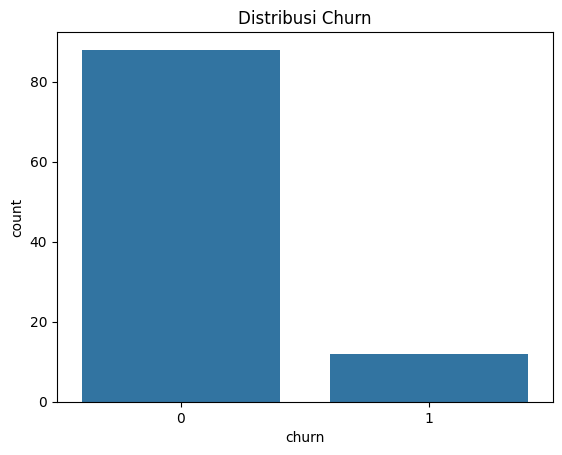

Churn Rate: 0.12


In [67]:
sns.countplot(x='churn', data=data)
plt.title("Distribusi Churn")
plt.show()

churn_rate = data['churn'].mean()
print("Churn Rate:", churn_rate)

karena churn < 20%, maka data imbalance. untuk mengatasi data imbalance, bisa dilakukan SMOTE sebelum lanjut ke analisis klasifikasi

**EDA Univariat Pada Fitur Numerik**

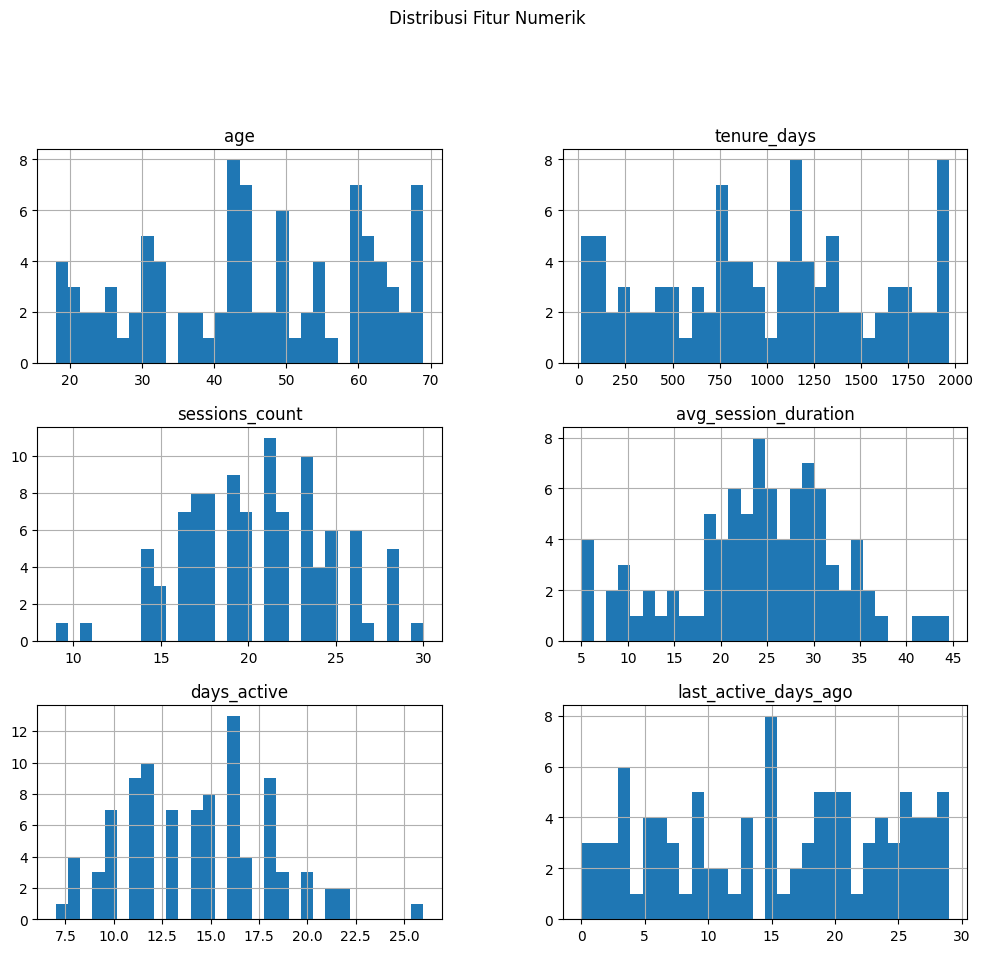

In [68]:
num_cols = ['age', 'tenure_days', 'sessions_count', 'avg_session_duration', 
            'days_active', 'last_active_days_ago']

data[num_cols].hist(bins=30, figsize=(12, 10))
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.show()


**EDA Univariat Variabel Kategorik**

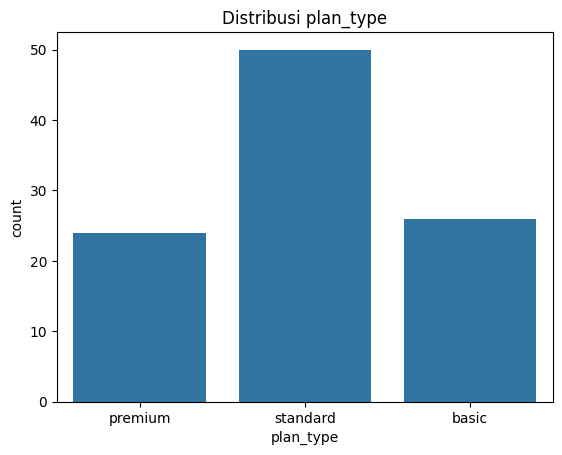

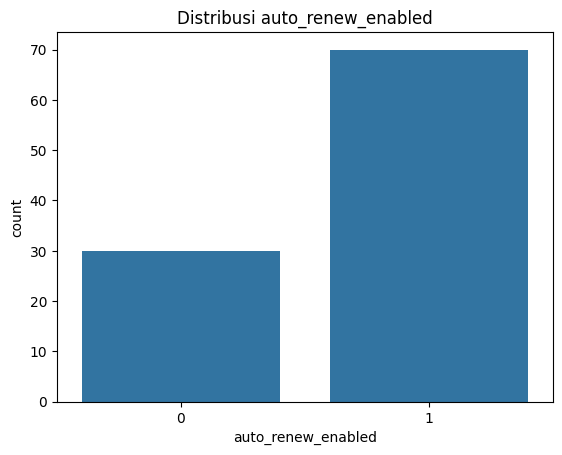

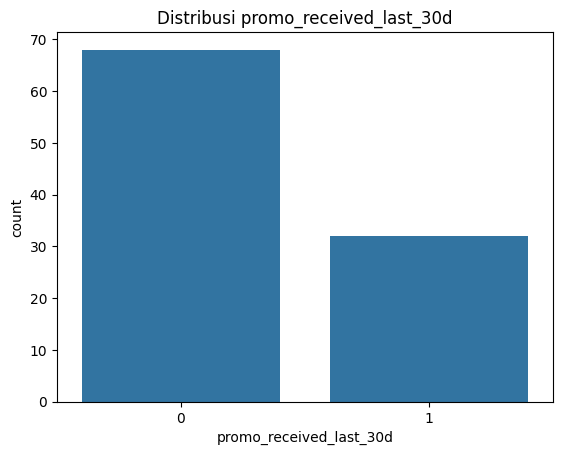

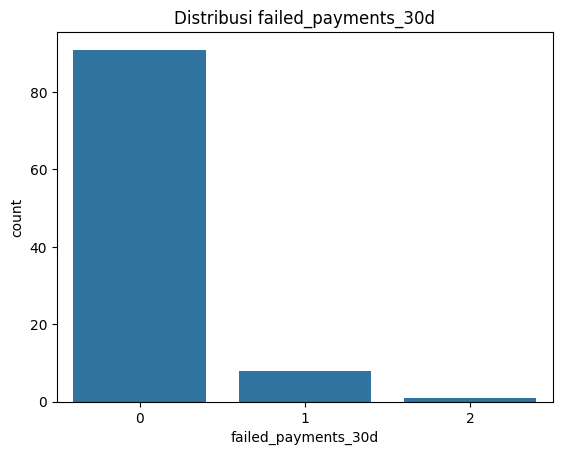

In [69]:
cat_cols = ['plan_type', 'auto_renew_enabled', 'promo_received_last_30d', 'failed_payments_30d']

for col in cat_cols:
    sns.countplot(x=col, data=data)
    plt.title(f"Distribusi {col}")
    plt.show()


**Korelasi Antar Variabel (Heatmap)**

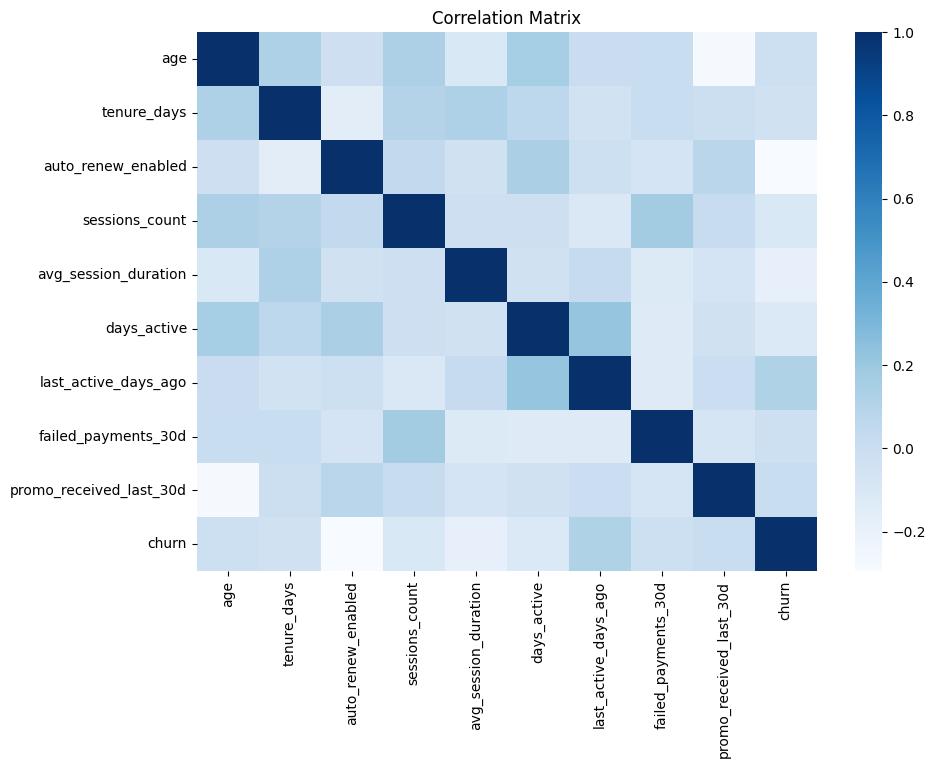

In [70]:
corr = data.corr(numeric_only=True)

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=False, cmap="Blues")
plt.title("Correlation Matrix")
plt.show()


**Churn vs Setiap Fitur Numerik**

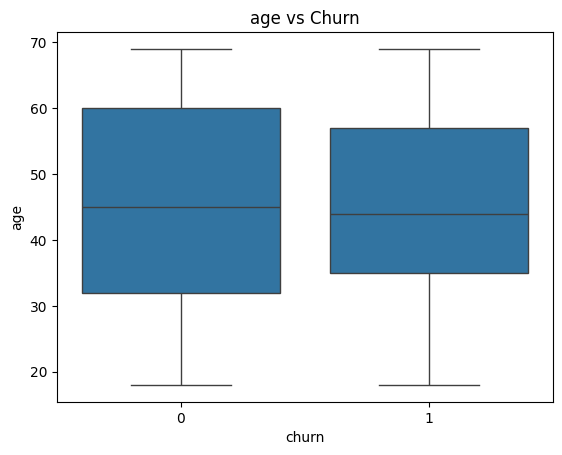

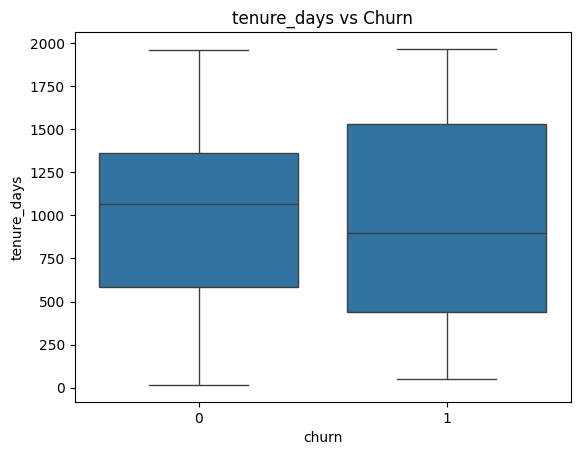

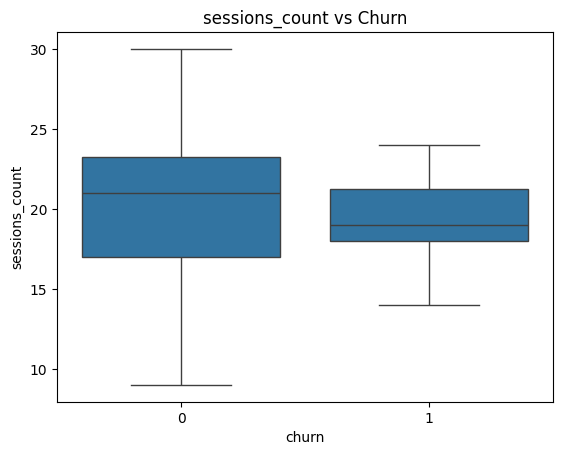

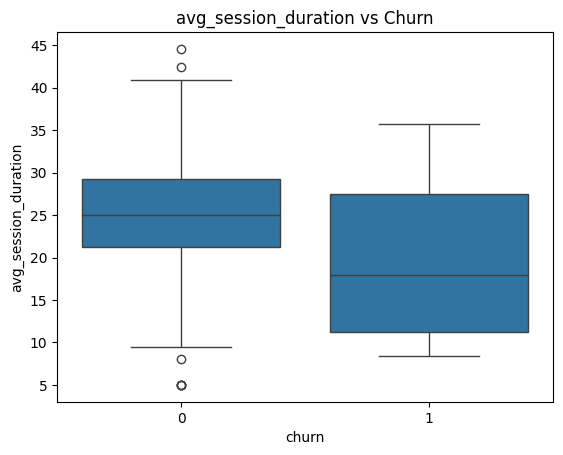

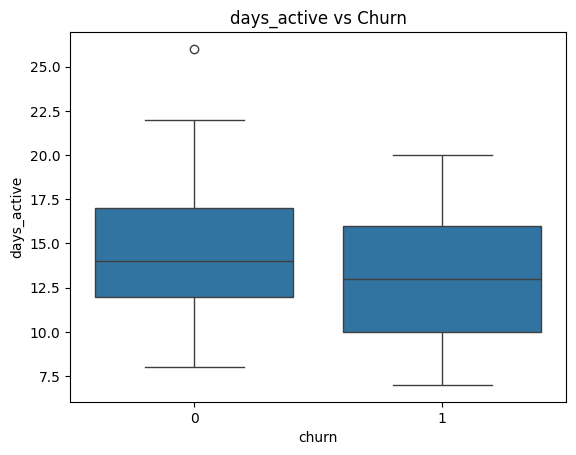

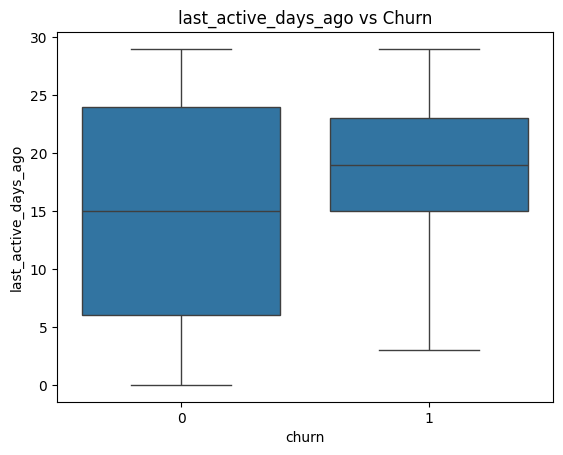

In [71]:
for col in num_cols:
    sns.boxplot(x='churn', y=col, data=data)
    plt.title(f"{col} vs Churn")
    plt.show()


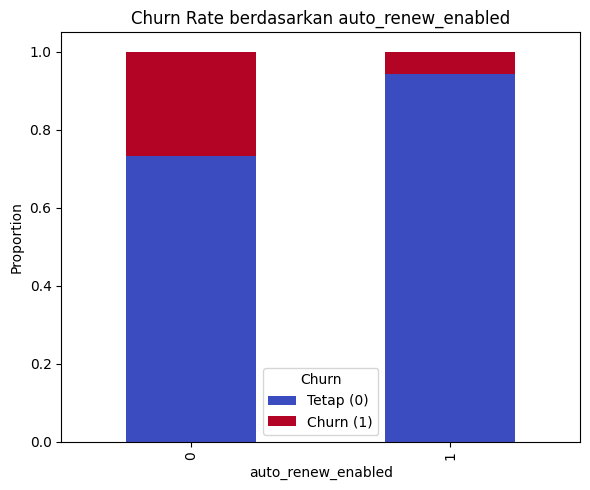

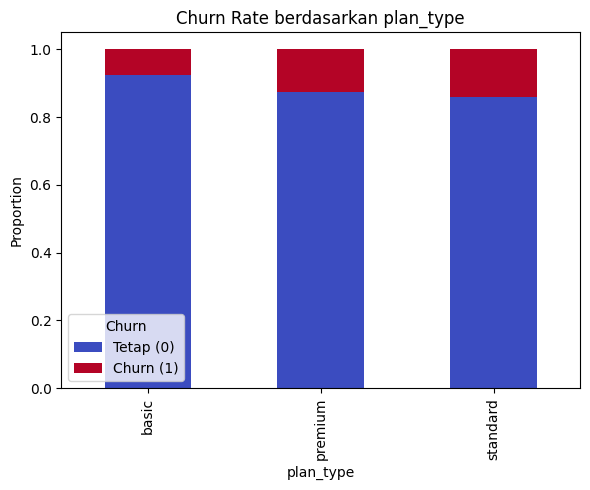

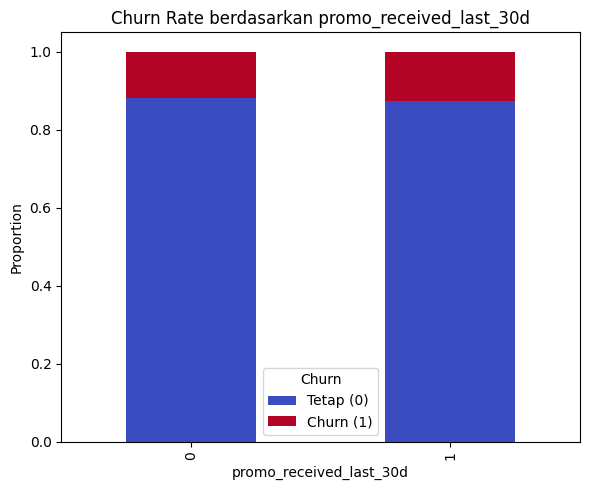

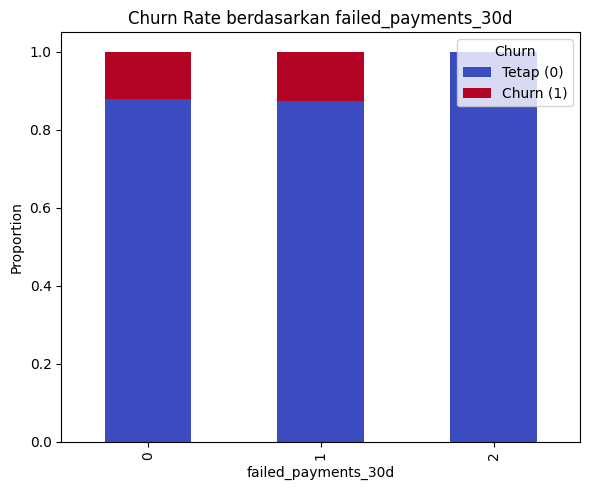

In [72]:
categorical_cols = ['auto_renew_enabled', 'plan_type', 'promo_received_last_30d', 'failed_payments_30d']

for col in categorical_cols:
    # membuat proporsi cross-tab
    ctab = pd.crosstab(data[col], data['churn'], normalize='index')

    # plot stacked bar
    ctab.plot(
        kind='bar',
        stacked=True,
        figsize=(6,5),
        colormap='coolwarm'
    )

    plt.title(f"Churn Rate berdasarkan {col}")
    plt.xlabel(col)
    plt.ylabel("Proportion")
    plt.legend(title="Churn", labels=["Tetap (0)", "Churn (1)"])
    plt.tight_layout()
    plt.show()


## **Membangun Model Klasifikasi**

### **1. MODEL 1 : Logistic Regression**

In [73]:
# ======================
# LOAD DATA
# ======================
data = pd.read_csv("D:/smt 5/ADS/FP/Data_Churn.csv")
data.head()

,age,tenure_days,plan_type,auto_renew_enabled,sessions_count,avg_session_duration,days_active,last_active_days_ago,failed_payments_30d,promo_received_last_30d,churn
0,67.0,1372.0,premium,1,22,19.512397,18.0,15,1,0,0
1,50.0,723.0,standard,1,23,27.339013,18.0,9,0,1,0
2,NaN,1286.0,standard,1,18,24.955683,14.0,5,0,0,0
3,64.0,1196.0,standard,0,20,NaN,11.0,2,0,0,0
4,48.0,217.0,premium,1,21,25.671213,12.0,19,0,0,0


**Imputasi Missing Values**

In [74]:
# ======================
# MICE IMPUTATION
# ======================
cols_to_impute = ['age', 'tenure_days', 'avg_session_duration', 'days_active']
data_subset = data[cols_to_impute + ['churn']]
np.random.seed(42)
mice_data = MICEData(data_subset)

for i in range(20):
    mice_data.update_all()

data_imputed = mice_data.data

data[cols_to_impute] = data_imputed[cols_to_impute]
print(data.isnull().sum())

age                        0
tenure_days                0
plan_type                  0
auto_renew_enabled         0
sessions_count             0
avg_session_duration       0
days_active                0
last_active_days_ago       0
failed_payments_30d        0
promo_received_last_30d    0
churn                      0
dtype: int64


Pilih kolom numerik yang ada missing value (cols_to_impute) + target (churn) → untuk MICE bisa memanfaatkan korelasi antar kolom.

**Feature Engineering**

In [75]:
# ======================
# FEATURE ENGINEERING
# ======================

# Hindari pembagian nol
data['tenure_days'] = data['tenure_days'].replace(0, 1)
data['days_active'] = data['days_active'].replace(0, 1)

# 1. Recency Ratio
data['recency_ratio'] = data['last_active_days_ago'] / data['tenure_days']

# 2. Activity Rate
data['activity_rate'] = data['days_active'] / data['tenure_days']

# 3. Session Intensity
data['session_intensity'] = data['sessions_count'] / data['days_active']

# 4. Avg Session per Active Day
data['avg_session_per_day'] = data['avg_session_duration'] / data['days_active']

# 5. Failed Payment Rate
data['failed_payment_rate'] = data['failed_payments_30d'] / data['tenure_days']

# 6. Binary Flags
data['is_new_user'] = (data['tenure_days'] < 90).astype(int)
data['high_activity'] = (data['days_active'] > data['days_active'].median()).astype(int)

print("=== FEATURE ENGINEERING DONE ===")
print(data.head())

=== FEATURE ENGINEERING DONE ===
    age  tenure_days plan_type  auto_renew_enabled  sessions_count  \
0  67.0       1372.0   premium                   1              22   
1  50.0        723.0  standard                   1              23   
2  30.0       1286.0  standard                   1              18   
3  64.0       1196.0  standard                   0              20   
4  48.0        217.0   premium                   1              21   

   avg_session_duration  days_active  last_active_days_ago  \
0             19.512397         18.0                    15   
1             27.339013         18.0                     9   
2             24.955683         14.0                     5   
3             22.302996         11.0                     2   
4             25.671213         12.0                    19   

   failed_payments_30d  promo_received_last_30d  churn  recency_ratio  \
0                    1                        0      0       0.010933   
1                    0     

**Memberikan informasi tambahan (features) untuk model agar lebih prediktif terhadap churn.**
- recency_ratio → berapa lama sejak terakhir aktif dibanding lama berlangganan, bisa menandakan risiko churn.
- activity_rate → proporsi hari aktif dibanding total tenure, indikasi loyalitas.
- session_intensity → jumlah sesi per hari aktif, aktivitas user.
- avg_session_per_day → rata-rata durasi sesi per hari aktif.
- failed_payment_rate → rasio pembayaran gagal → indikator masalah keuangan / risiko churn.
- is_new_user → flag user baru (<90 hari).
- high_activity → flag user dengan aktivitas di atas median.

**Encoding Kategori**

In [76]:
# ======================
# DUMMY ENCODING
# ======================
data_encoded = pd.get_dummies(data, columns=['plan_type'], drop_first=True)
data_encoded

,age,tenure_days,auto_renew_enabled,sessions_count,avg_session_duration,days_active,last_active_days_ago,failed_payments_30d,promo_received_last_30d,churn,recency_ratio,activity_rate,session_intensity,avg_session_per_day,failed_payment_rate,is_new_user,high_activity,plan_type_premium,plan_type_standard
0,67.0,1372.0,1,22,19.512397,18.0,15,1,0,0,0.010933,0.013120,1.222222,1.084022,0.000729,0,1,True,False
1,50.0,723.0,1,23,27.339013,18.0,9,0,1,0,0.012448,0.024896,1.277778,1.518834,0.000000,0,1,False,True
2,30.0,1286.0,1,18,24.955683,14.0,5,0,0,0,0.003888,0.010886,1.285714,1.782549,0.000000,0,0,False,True
3,64.0,1196.0,0,20,22.302996,11.0,2,0,0,0,0.001672,0.009197,1.818182,2.027545,0.000000,0,0,False,True
4,48.0,217.0,1,21,25.671213,12.0,19,0,0,0,0.087558,0.055300,1.750000,2.139268,0.000000,0,0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,46.0,744.0,1,19,34.062390,13.0,15,0,0,0,0.020161,0.017473,1.461538,2.620184,0.000000,0,0,False,True
96,55.0,1607.0,1,23,44.574452,11.0,19,0,0,0,0.011823,0.006845,2.090909,4.052223,0.000000,0,0,False,False
97,44.0,61.0,1,14,23.407327,10.0,13,0,0,0,0.213115,0.163934,1.400000,2.340733,0.000000,1,0,False,True
98,49.0,1814.0,1,24,24.515993,9.0,27,0,0,0,0.014884,0.004961,2.666667,2.723999,0.000000,0,0,True,False


**Train-Test Split**

In [77]:
# ======================
# TRAIN TEST SPLIT
# ======================
X = data_encoded.drop("churn", axis=1)
y = data_encoded["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ======================
# MENAMPILKAN OUTPUT
# ======================
print("Jumlah data total       :", X.shape[0])
print("Jumlah data training    :", X_train.shape[0])
print("Jumlah data testing     :", X_test.shape[0])

print("\nDistribusi target (Train):")
print(y_train.value_counts(normalize=True))

print("\nDistribusi target (Test):")
print(y_test.value_counts(normalize=True))

Jumlah data total       : 100
Jumlah data training    : 80
Jumlah data testing     : 20

Distribusi target (Train):
churn
0    0.875
1    0.125
Name: proportion, dtype: float64

Distribusi target (Test):
churn
0    0.9
1    0.1
Name: proportion, dtype: float64


**Mengatasi Data Imbalance**

In [78]:
# ======================
# SMOTE BALANCING
# ======================
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(pd.Series(y_train_res).value_counts())

churn
0    70
1    70
Name: count, dtype: int64


Mengurangi bias model terhadap kelas mayoritas (churn=0).

**Normalisasi Data**

In [79]:
# ======================
# SCALING
# ======================
scaler = StandardScaler()
X_train_res[num_cols] = scaler.fit_transform(X_train_res[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("=== Data Training Setelah Scaling ===")
print(X_train_res[num_cols].head())

print("\n=== Data Testing Setelah Scaling ===")
print(X_test[num_cols].head())


=== Data Training Setelah Scaling ===
        age  tenure_days  sessions_count  avg_session_duration  days_active  \
0 -0.334055     0.388508       -0.521392             -1.974595    -1.038514   
1  0.914748     1.959413       -1.093900              0.457054     1.530140   
2 -0.113678     0.946542        0.051117              0.793389     0.759544   
3  0.253617    -1.553145       -0.521392             -1.210650     1.530140   
4 -1.729776    -1.591367        1.482388             -0.009223    -0.011052   

   last_active_days_ago  
0             -1.525417  
1             -0.018832  
2             -0.521027  
3              0.734460  
4             -1.399868  

=== Data Testing Setelah Scaling ===
         age  tenure_days  sessions_count  avg_session_duration  days_active  \
94 -1.215563     0.973298       -1.093900              0.303747     0.759544   
82  1.575879     1.923102        1.482388              0.333174    -0.524783   
92 -0.334055    -1.568434        0.051117            

### **MODEL : Logistic Regression**

In [80]:
# ======================
# LOGISTIC REGRESSION + CV
# ======================
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold, cross_val_score

logreg = LogisticRegression(max_iter=500)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
roc_auc_scores = cross_val_score(logreg, X_train_res, y_train_res, cv=cv, scoring='roc_auc')

print("Average ROC-AUC CV:", roc_auc_scores.mean())

logreg.fit(X_train_res, y_train_res)

y_pred = logreg.predict(X_test)
y_proba = logreg.predict_proba(X_test)[:,1]

print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_proba))



Average ROC-AUC CV: 0.9336734693877551
=== Classification Report ===
              precision    recall  f1-score   support

           0       0.89      0.89      0.89        18
           1       0.00      0.00      0.00         2

    accuracy                           0.80        20
   macro avg       0.44      0.44      0.44        20
weighted avg       0.80      0.80      0.80        20

=== Confusion Matrix ===
[[16  2]
 [ 2  0]]
ROC-AUC: 0.5833333333333333


1️⃣ Average ROC-AUC CV: 0.93

Hasil cross-validation pada data train menunjukkan ROC-AUC sebesar 0.93, yang menandakan bahwa model logistic regression mampu memisahkan pelanggan yang berisiko churn dan tidak dengan sangat baik pada data yang seimbang.

2️⃣ Classification Report (Test Set):

Berdasarkan classification report pada test set, model berhasil memprediksi sebagian besar pelanggan non-churn dengan precision dan recall sekitar 0.89. Namun, model gagal memprediksi pelanggan churn, dengan precision, recall, dan f1-score masing-masing 0.00. Hal ini menunjukkan bahwa meskipun model sangat baik pada data train yang seimbang, performanya menurun drastis pada data asli yang sangat imbalanced, terutama karena jumlah sample churn di test set sangat sedikit (hanya 2 orang).

3️⃣ Confusion Matrix

Confusion matrix mengkonfirmasi hasil classification report. Model berhasil mengklasifikasikan 16 pelanggan non-churn dengan benar, namun salah memprediksi 2 pelanggan non-churn sebagai churn, dan gagal memprediksi 2 pelanggan churn sama sekali. Tidak ada true positive untuk churn. Kondisi ini menandakan bahwa model terlalu condong ke kelas mayoritas dan kurang mampu mengenali kelas minoritas pada data test asli, sehingga prediksi churn tidak efektif.

4️⃣ ROC-AUC Test Set: 0.5

Nilai ROC-AUC sebesar 0.5 pada test set menunjukkan bahwa model tidak mampu membedakan pelanggan churn dan non-churn di data test. Nilai ini setara dengan random guessing. Penyebab utama adalah jumlah pelanggan churn yang sangat sedikit di test set, sehingga probabilitas prediksi model tidak bervariasi dan ROC curve menjadi degenerate. Hal ini menggarisbawahi pentingnya jumlah sample minoritas yang memadai untuk evaluasi model yang handal.

In [81]:
# ======================
# LOGIT MODEL DETAIL
# ======================
X_train_sm = sm.add_constant(X_train_res.astype(float))
y_train_sm = y_train_res.astype(float)

logit_model = sm.Logit(y_train_sm, X_train_sm)
result = logit_model.fit()
print(result.summary2())

coef_df = pd.DataFrame({
    "Feature": X_train_sm.columns,
    "Coefficient": result.params,
    "Odds_Ratio": np.exp(result.params),
    "p_value": result.pvalues
}).sort_values(by="Odds_Ratio", ascending=False)

print(coef_df)

         Current function value: 0.188331
         Iterations: 35
                                  Results: Logit
Model:                    Logit                  Method:                 MLE       
Dependent Variable:       churn                  Pseudo R-squared:       0.728     
Date:                     2025-12-13 14:41       AIC:                    90.7327   
No. Observations:         140                    BIC:                    146.6239  
Df Model:                 18                     Log-Likelihood:         -26.366   
Df Residuals:             121                    LL-Null:                -97.041   
Converged:                0.0000                 LLR p-value:            3.5192e-21
No. Iterations:           35.0000                Scale:                  1.0000    
-----------------------------------------------------------------------------------
                          Coef.     Std.Err.     z    P>|z|     [0.025     0.975]  
---------------------------------------------

c:\Users\SISTEM\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Pseudo R-squared: 0.717
Model menjelaskan sekitar 71,7% variasi dalam probabilitas churn dibandingkan model null (tanpa predictor).


- **Age** : p-value (0.5590) dari variabel ini tidak signifikan, sehingga usia pelanggan bukan faktor penting dalam memprediksi churn di dataset ini.
- **Tenure_days** : p-value (0.0012) sangat signifikan, dengan koefisien negatif. Semakin lama pelanggan berlangganan, probabilitas churn menurun drastis, menandakan loyalitas waktu langganan adalah faktor proteksi utama.
- **Auto_renew_enabled** : p-value (0.0006) sangat signifikan, dengan koefisien negatif. Pelanggan yang mengaktifkan auto-renew hampir pasti bertahan, sehingga auto-renew merupakan fitur proteksi churn yang efektif.
- **Sessions_count** : p-value (0.0031) signifikan, dengan koefisien negatif. Semakin sering pelanggan melakukan sesi, risiko churn menurun, menunjukkan engagement tinggi menurunkan risiko churn.
- **Avg_session_duration** : p-value (0.0383) signifikan, koefisien negatif. Semakin lama rata-rata durasi sesi, probabilitas churn menurun, menandakan pengalaman pengguna yang baik meningkatkan retensi.
- **Days_active** : p-value (0.0048) signifikan, koefisien positif. Semakin banyak hari aktif, probabilitas churn meningkat, kemungkinan menunjukkan bahwa pelanggan yang sangat aktif namun tidak loyal tetap berisiko berhenti menggunakan layanan.
- **Last_active_days_ago** : p-value (0.0248) signifikan, koefisien positif. Semakin lama sejak terakhir aktif, risiko churn meningkat, sehingga recency aktivitas pelanggan adalah indikator penting untuk retensi.
- **Failed_payments_30d** : p-value (0.4966) tidak signifikan. Jumlah gagal pembayaran dalam 30 hari terakhir tidak berpengaruh signifikan terhadap churn di dataset ini.
- **Promo_received_last_30d** : p-value (0.0054) signifikan, dengan koefisien negatif. Pelanggan yang menerima promo dalam 30 hari terakhir memiliki probabilitas churn yang lebih rendah, menunjukkan strategi promosi dapat membantu meningkatkan retensi pelanggan.
- **Recency_ratio** : p-value (0.8777) tidak signifikan, dengan koefisien positif. Rasio recency terhadap tenure tidak memiliki pengaruh signifikan terhadap probabilitas churn, sehingga variabel ini kurang informatif dalam memprediksi churn.
- **Activity_rate** : p-value (0.4517) tidak signifikan, dengan koefisien negatif. Rasio aktivitas terhadap tenure tidak berpengaruh signifikan terhadap churn, sehingga tidak menjadi faktor utama dalam analisis retensi pelanggan.
- **Session_intensity** : p-value (0.0032) signifikan, dengan koefisien positif. Semakin tinggi intensitas sesi (jumlah sesi per hari aktif), probabilitas churn meningkat, yang bisa menunjukkan pelanggan dengan penggunaan tinggi tapi belum loyal tetap berisiko churn.
- **Avg_session_per_day** : p-value (0.8065) tidak signifikan, dengan koefisien negatif. Rata-rata durasi sesi per hari tidak berpengaruh signifikan terhadap churn, sehingga variabel ini tidak menjadi indikator penting retensi.
- **Failed_payment_rate** : p-value (0.3522) tidak signifikan, dengan koefisien negatif. Rasio gagal bayar tidak memberikan pengaruh signifikan terhadap probabilitas churn, sehingga kurang relevan dalam memprediksi perilaku berhenti berlangganan.
- **Is_new_user** : p-value (0.3256) tidak signifikan, dengan koefisien positif. Pelanggan baru cenderung lebih berisiko churn, namun efek ini tidak signifikan secara statistik.
- **High_activity** : p-value (0.3263) tidak signifikan, dengan koefisien positif. Pelanggan dengan aktivitas tinggi sedikit lebih berisiko churn, tetapi variabel ini tidak signifikan dan tidak dapat dijadikan indikator kuat.
- **Plan_type_premium** : p-value (0.2423) tidak signifikan, dengan koefisien positif. Pelanggan paket premium sedikit lebih berisiko churn, namun efeknya tidak signifikan secara statistik.
- **Plan_type_standard** : p-value (0.1251) tidak signifikan, dengan koefisien positif. Pelanggan paket standard cenderung memiliki risiko churn lebih tinggi dibanding paket dasar, namun tidak signifikan secara statistik.

**Variabel Signifikan**
1. **Auto_renew_enabled** (p=0.0006, koef negatif)

Variabel paling signifikan. Pelanggan yang mengaktifkan auto-renew hampir pasti bertahan, sehingga fitur ini adalah proteksi churn paling kuat.

2. **Tenure_days** (p=0.0012, koef negatif)

Semakin lama pelanggan berlangganan, risiko churn menurun drastis. Loyalitas waktu langganan adalah faktor proteksi utama terhadap churn.

3. **Sessions_count** (p=0.0031, koef negatif)

Semakin sering pelanggan melakukan sesi, risiko churn menurun. Menunjukkan engagement tinggi menurunkan risiko churn.

4. **Session_intensity** (p=0.0032, koef positif)

Semakin tinggi intensitas sesi (jumlah sesi per hari aktif), probabilitas churn meningkat. Menunjukkan pelanggan sangat aktif tapi belum loyal tetap berisiko churn.

5. **Days_active** (p=0.0048, koef positif)

Semakin banyak hari aktif, probabilitas churn meningkat, kemungkinan menunjukkan pelanggan aktif namun tidak loyal tetap berisiko berhenti.

6. **Promo_received_last_30d** (p=0.0054, koef negatif)

Pelanggan yang menerima promo memiliki probabilitas churn lebih rendah, menunjukkan promosi efektif untuk retensi.

7. **Last_active_days_ago** (p=0.0248, koef positif)

Semakin lama sejak terakhir aktif, risiko churn meningkat. Recency aktivitas adalah indikator penting untuk retensi.

8. **Avg_session_duration** (p=0.0383, koef negatif)

Semakin lama durasi rata-rata sesi, probabilitas churn menurun, menandakan pengalaman pengguna yang baik meningkatkan retensi.


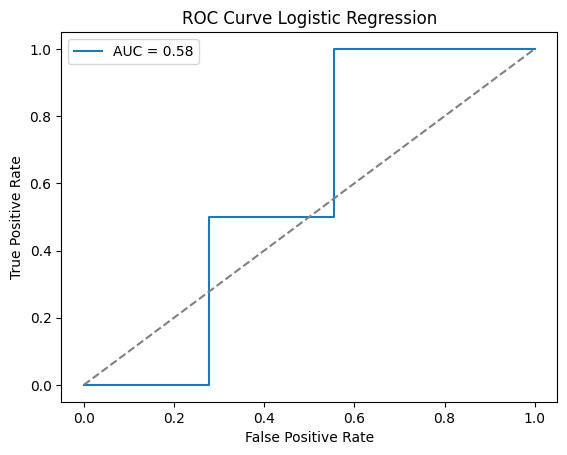

In [82]:
# ======================
# ROC CURVE PLOT
# ======================
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_proba):.2f}')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Logistic Regression')
plt.legend()
plt.show()


In [83]:
# ======================
# PSEUDO R-SQUARED
# ======================
ll_model = result.llf          # log-likelihood model
ll_null = result.llnull        # log-likelihood null model
n = X_train_sm.shape[0]

# McFadden R²
mcfadden_r2 = 1 - (ll_model / ll_null)

# Cox & Snell R²
cox_snell_r2 = 1 - np.exp((ll_null - ll_model) * 2 / n)

# Nagelkerke R²
nagelkerke_r2 = cox_snell_r2 / (1 - np.exp(-ll_null*2/n))

print("\n=== PSEUDO R-SQUARED ===")
print(f"McFadden R²: {mcfadden_r2:.4f}")
print(f"Cox & Snell R²: {cox_snell_r2:.4f}")
print(f"Nagelkerke R²: {nagelkerke_r2:.4f}")



=== PSEUDO R-SQUARED ===
McFadden R²: 0.7283
Cox & Snell R²: 0.6356
Nagelkerke R²: -0.2119


## **MODEL : XGBOOST**

In [84]:
# ==========================
# XGBOOST — ADVANCED MODEL
# ==========================

from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# ==========================
# SCALE_POS_WEIGHT
# ==========================
neg = (y_train_res == 0).sum()
pos = (y_train_res == 1).sum()
scale_pos_weight = neg / pos

print("scale_pos_weight =", scale_pos_weight)

# ==========================
# PARAMETER SEARCH (RANDOMIZED)
# ==========================

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'colsample_bytree': [0.5, 0.7, 1.0],
    'subsample': [0.7, 1.0],
    'gamma': [0, 1, 5],
}

xgb_base = XGBClassifier(
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

rand_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    scoring='roc_auc',
    n_iter=20,
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

rand_search.fit(X_train_res, y_train_res)

print("Best Params:", rand_search.best_params_)

best_xgb = rand_search.best_estimator_

# ==========================
# FIT MODEL
# ==========================
best_xgb.fit(X_train_res, y_train_res)

# ==========================
# PREDICT PROBABILITY
# ==========================
y_prob = best_xgb.predict_proba(X_test)[:, 1]

# ==========================
# THRESHOLD TUNING (Youden Index)
# ==========================
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
youden_index = tpr - fpr
best_threshold = thresholds[np.argmax(youden_index)]

print("\nBEST THRESHOLD =", best_threshold)

# apply threshold
y_pred = (y_prob >= best_threshold).astype(int)

# ==========================
# EVALUATION
# ==========================
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred))

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== ROC-AUC ===")
print(roc_auc_score(y_test, y_prob))


scale_pos_weight = 1.0
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Params: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.7}

BEST THRESHOLD = 0.14180703

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       1.00      0.72      0.84        18
           1       0.29      1.00      0.44         2

    accuracy                           0.75        20
   macro avg       0.64      0.86      0.64        20
weighted avg       0.93      0.75      0.80        20


=== CONFUSION MATRIX ===
[[13  5]
 [ 0  2]]

=== ROC-AUC ===
0.7222222222222222


Model XGBoost yang dibangun menghasilkan kombinasi parameter terbaik berupa subsample 0.7, colsample_bytree 0.7, max_depth 5, learning_rate 0.05, n_estimators 100, dan gamma 0. Kombinasi ini menunjukkan bahwa model bekerja dengan pohon yang cukup kompleks namun tetap dijaga agar tidak overfitting dengan cara mengambil hanya 70% data dan 70% fitur pada setiap pohon. Learning rate yang kecil membuat proses pembelajaran berlangsung lebih perlahan tetapi stabil, sehingga pola yang dipelajari lebih halus dan tidak terlalu agresif. Gamma bernilai 0 menunjukkan bahwa model tidak membatasi proses pemecahan node, sehingga lebih mudah menemukan pola-pola kecil dalam data.

Model juga memberikan best threshold sebesar 0.1418, jauh lebih rendah dari threshold default 0.5. Ini berarti model akan mengklasifikasikan seseorang sebagai “churn” meskipun probabilitasnya hanya 14%. Threshold rendah seperti ini membuat model lebih agresif dalam mendeteksi churn, yang cocok digunakan bila tujuan bisnis adalah memastikan tidak ada pelanggan berisiko tinggi yang terlewat, walaupun harus menerima peningkatan false positive.

Hasil evaluasi menunjukkan bahwa model memiliki performa yang kuat dalam mendeteksi churn. Hal ini terlihat dari recall kelas churn yang mencapai 100%, artinya semua pelanggan yang benar-benar churn berhasil ditandai oleh model. Namun, precision churn hanya sebesar 29%, menunjukkan bahwa cukup banyak pelanggan non-churn yang salah diklasifikasikan sebagai churn. Kondisi ini wajar dan merupakan konsekuensi langsung dari penggunaan threshold rendah. Sementara itu, performa kelas non-churn tetap cukup baik dengan precision 100% dan recall 72%, meskipun terdapat beberapa kasus non-churn yang salah diprediksi sebagai churn.

Confusion matrix memperlihatkan bahwa dari 18 pelanggan non-churn, sebanyak 13 berhasil diprediksi dengan benar, sementara 5 lainnya salah diklasifikasikan sebagai churn. Sebaliknya, kedua pelanggan yang benar-benar churn berhasil diprediksi dengan tepat, tanpa ada satu pun kasus churn yang terlewat. Dengan demikian, model berhasil menciptakan perlindungan maksimal terhadap risiko churn meskipun dengan trade-off berupa meningkatnya false positive.

Secara keseluruhan, nilai ROC-AUC sebesar 0.72 menunjukkan bahwa model memiliki kemampuan diskriminatif yang cukup baik dalam membedakan pelanggan churn dan non-churn. Meskipun tidak mencapai performa tinggi, nilai ini sudah cukup kompetitif terutama pada dataset kecil dan tidak seimbang seperti ini. Model ini sangat cocok digunakan bila prioritas utama adalah mendeteksi sebanyak mungkin pelanggan churn untuk kepentingan strategi retensi.


=== FEATURE IMPORTANCE ===
                    feature  importance
2        auto_renew_enabled    0.172669
8   promo_received_last_30d    0.119718
17       plan_type_standard    0.087845
13      failed_payment_rate    0.079914
4      avg_session_duration    0.066207
16        plan_type_premium    0.064673
1               tenure_days    0.057447
3            sessions_count    0.052508
11        session_intensity    0.042568
6      last_active_days_ago    0.040114
0                       age    0.038320
15            high_activity    0.037278
12      avg_session_per_day    0.034649
9             recency_ratio    0.032463
10            activity_rate    0.028266
7       failed_payments_30d    0.025712
5               days_active    0.019648
14              is_new_user    0.000000


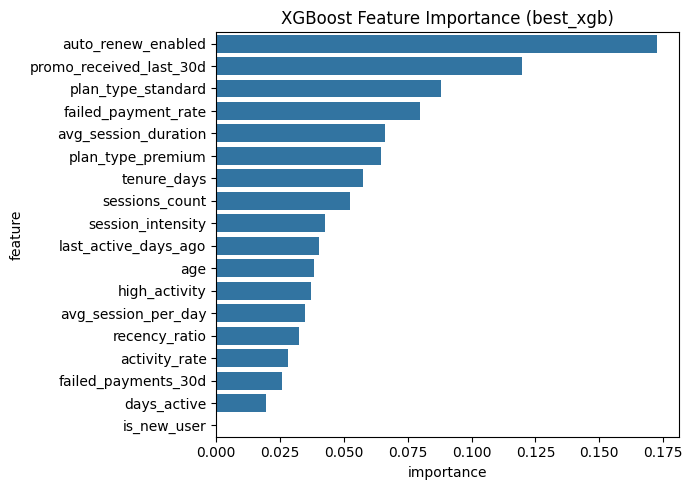

In [85]:
# ambil importance
importances = best_xgb.feature_importances_
features = X_train_res.columns

# buat dataframe
fi_df = pd.DataFrame({
    "feature": features,
    "importance": importances
}).sort_values(by="importance", ascending=False)

print("\n=== FEATURE IMPORTANCE ===")
print(fi_df)

# plot
plt.figure(figsize=(7, 5))
sns.barplot(x="importance", y="feature", data=fi_df)
plt.title("XGBoost Feature Importance (best_xgb)")
plt.tight_layout()
plt.show()

### **MODEL FIX YANG DIGUNAKAN XGBOOST**

Model Logistic Regression menunjukkan bahwa ia memiliki kemampuan generalisasi yang cukup kuat berdasarkan nilai Average ROC-AUC CV sebesar 0.93, yang berarti model cukup baik dalam membedakan kelas churn dan non-churn pada data pelatihan. Namun, ketika diuji pada data testing, performanya jauh menurun dengan ROC-AUC hanya 0.58, menunjukkan bahwa model tidak dapat menangkap pola churn yang sebenarnya pada data baru. Logistic Regression juga gagal mendeteksi pelanggan churn sama sekali, terlihat dari recall = 0% dan 0 dari 2 pelanggan churn berhasil diprediksi. Hal ini menandakan bahwa meskipun model stabil secara cross-validation, ia tidak cukup fleksibel untuk mempelajari pola churn pada dataset kecil dan sangat tidak seimbang seperti ini.

Di sisi lain, model XGBoost memberikan hasil yang jauh lebih baik dalam mendeteksi kelas minoritas. Walaupun akurasinya sedikit lebih rendah (75%), XGBoost berhasil mencapai recall 100% untuk kelas churn, artinya tidak ada satu pun pelanggan churn yang terlewat. Penggunaan threshold rendah (0.14) membuat model lebih agresif dalam menandai pelanggan berisiko, yang sesuai untuk kasus bisnis yang lebih memprioritaskan menghindari kehilangan pelanggan daripada memaksimalkan akurasi keseluruhan. Namun, trade-off dari strategi ini adalah meningkatnya false positive sehingga sebagian pelanggan non-churn diprediksi churn (5 dari 18). Meskipun demikian, ROC-AUC XGBoost = 0.72, yang berarti model lebih baik dalam memisahkan kelas dibanding logistic regression pada data uji.

Secara keseluruhan, Logistic Regression lebih stabil pada training, tetapi tidak mampu mengenali churn di data testing. Sebaliknya, XGBoost jauh lebih efektif untuk deteksi churn, terutama karena ia mampu menangkap non-linearitas, interaksi fitur, dan pola kompleks yang tidak mampu ditangkap Logistic Regression. Untuk kasus bisnis yang ingin fokus pada retensi pelanggan, XGBoost menjadi model yang lebih realistis dan lebih berguna.

In [86]:
# ======================
# RANDOM FOREST MODEL
# ======================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Inisialisasi model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    class_weight='balanced'  # opsional karena sudah SMOTE, tapi oke
)

# Train model
rf_model.fit(X_train_res, y_train_res)

# Prediksi
y_pred = rf_model.predict(X_test)

# ======================
# EVALUASI
# ======================
print("=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred))

print("\n=== AKURASI ===")
print(accuracy_score(y_test, y_pred))


=== CONFUSION MATRIX ===
[[17  1]
 [ 2  0]]

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.89      0.94      0.92        18
           1       0.00      0.00      0.00         2

    accuracy                           0.85        20
   macro avg       0.45      0.47      0.46        20
weighted avg       0.81      0.85      0.83        20


=== AKURASI ===
0.85


## **JAWAB SOAL**

### **1. Siapa pelanggan yang paling berisiko churn?**

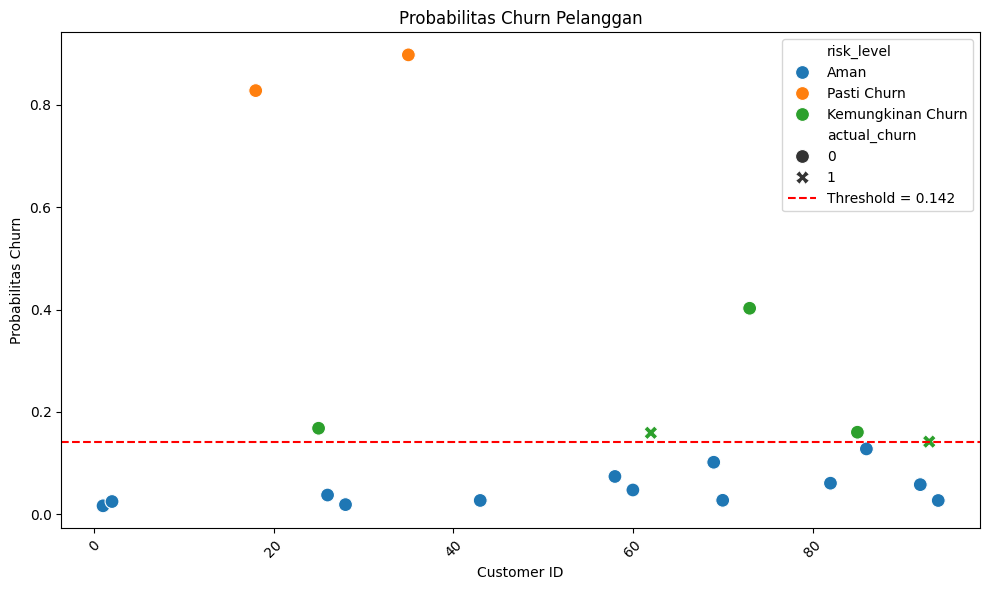

In [87]:
# ======================
# Buat DataFrame probabilitas
# ======================
prob_df = pd.DataFrame({
    'customer_id': X_test.index,
    'churn_prob': y_prob,  # probabilitas hasil predict_proba
    'actual_churn': y_test
})

# ======================
# Kategorikan risiko
# ======================
prob_df['risk_level'] = 'Aman'
prob_df.loc[prob_df['churn_prob'] >= best_threshold, 'risk_level'] = 'Kemungkinan Churn'
prob_df.loc[prob_df['churn_prob'] >= 0.7, 'risk_level'] = 'Pasti Churn'  # threshold tinggi untuk "pasti"

# ======================
# Plot
# ======================
plt.figure(figsize=(10,6))
sns.scatterplot(data=prob_df, x='customer_id', y='churn_prob', hue='risk_level', style='actual_churn', s=100)
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Threshold = {best_threshold:.3f}')
plt.title('Probabilitas Churn Pelanggan')
plt.xlabel('Customer ID')
plt.ylabel('Probabilitas Churn')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


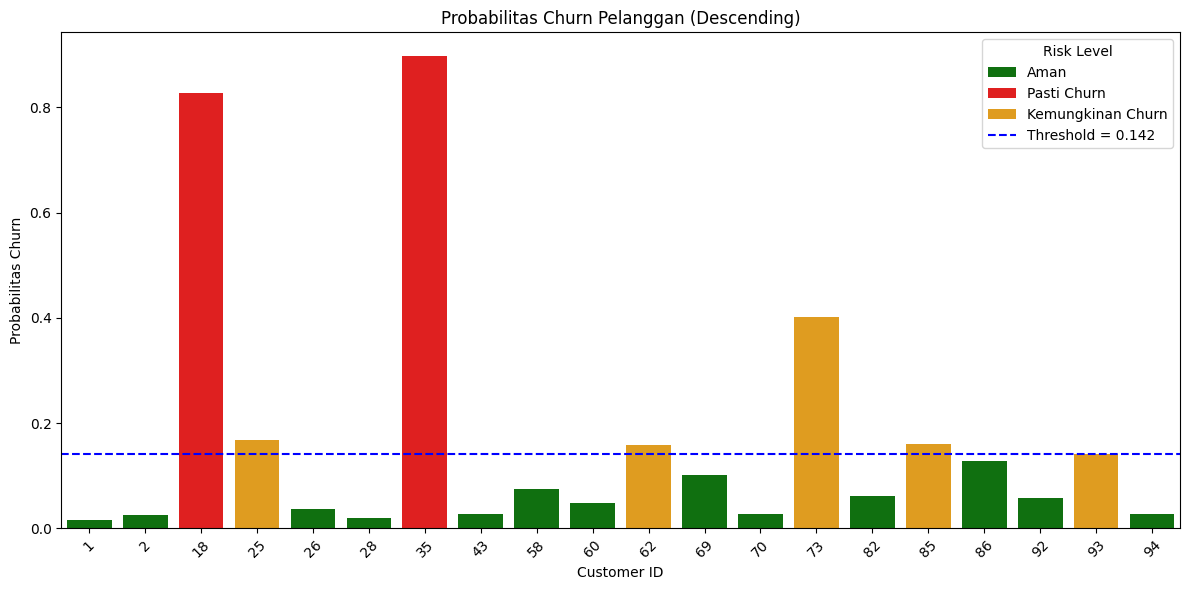

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ======================
# Buat DataFrame probabilitas
# ======================
prob_df = pd.DataFrame({
    'customer_id': X_test.index,
    'churn_prob': y_prob,  # probabilitas hasil predict_proba
    'actual_churn': y_test
})

# ======================
# Urut descending berdasarkan probabilitas churn
# ======================
prob_df = prob_df.sort_values(by='churn_prob', ascending=False).reset_index(drop=True)

# ======================
# Kategorikan risiko
# ======================
prob_df['risk_level'] = 'Aman'
prob_df.loc[prob_df['churn_prob'] >= best_threshold, 'risk_level'] = 'Kemungkinan Churn'
prob_df.loc[prob_df['churn_prob'] >= 0.7, 'risk_level'] = 'Pasti Churn'  # threshold tinggi untuk "pasti"

# ======================
# Barplot
# ======================
plt.figure(figsize=(12,6))
sns.barplot(data=prob_df, x='customer_id', y='churn_prob', hue='risk_level', dodge=False, palette={'Aman':'green','Kemungkinan Churn':'orange','Pasti Churn':'red'})
plt.axhline(best_threshold, color='blue', linestyle='--', label=f'Threshold = {best_threshold:.3f}')
plt.title('Probabilitas Churn Pelanggan (Descending)')
plt.xlabel('Customer ID')
plt.ylabel('Probabilitas Churn')
plt.xticks(rotation=45)
plt.legend(title='Risk Level')
plt.tight_layout()
plt.show()


Berdasarkan visualisasi tersebut, pelanggan yang beresiko churn adalah 2 pelanggan dengan nomor ID 18 dan 35

### **2. Faktor apa yang paling memengaruhi churn?**

C:\Users\SISTEM\AppData\Local\Temp\ipykernel_24896\126841249.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='importance', y='feature', palette='viridis')


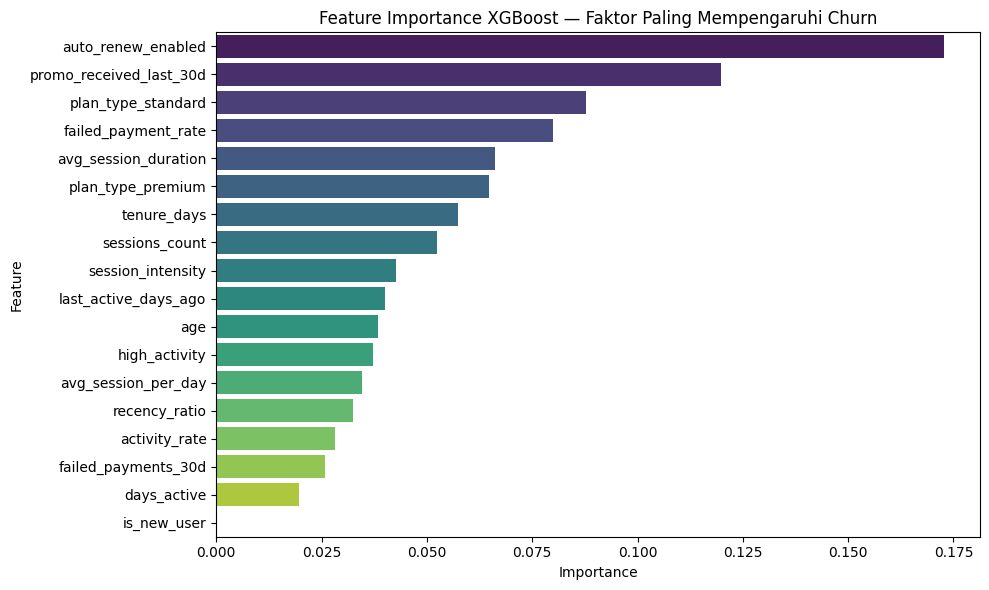

In [89]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ======================
# Feature Importance
# ======================
importance_df = pd.DataFrame({
    'feature': X_train_res.columns,
    'importance': best_xgb.feature_importances_
})

# Urut descending
importance_df = importance_df.sort_values(by='importance', ascending=False)

# ======================
# Plot
# ======================
plt.figure(figsize=(10,6))
sns.barplot(data=importance_df, x='importance', y='feature', palette='viridis')
plt.title('Feature Importance XGBoost — Faktor Paling Mempengaruhi Churn')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Berdasarkan feature importance XGBoost:

- auto_renew_enabled	0.173	Pelanggan yang tidak mengaktifkan auto-renew paling berisiko berhenti.
- promo_received_last_30d	0.120	Tidak menerima promo baru-baru ini meningkatkan risiko churn.
- plan_type_standard	0.088	Pelanggan paket standard lebih berisiko dibanding paket dasar/premium.
- failed_payment_rate	0.080	Rasio gagal bayar juga berpengaruh, walaupun lebih kecil.
- avg_session_duration	0.066	Sesi yang lebih singkat menandakan engagement rendah → risiko churn naik.

Jadi faktor paling dominan adalah auto-renew, promo terbaru, tipe paket, dan engagement (sesi/durasi).

### **3. Bagaimana trade-off antara false positive dan false negative?**

Artinya: ketika kita bikin model prediksi churn, kita harus memilih threshold probabilitas untuk menentukan siapa yang kita prediksi akan churn (1) dan siapa yang tidak (0). Masalahnya, tidak ada threshold yang sempurna, sehingga selalu ada kompromi antara dua jenis kesalahan:

False Positive (FP) → Kita prediksi pelanggan akan churn, tapi sebenarnya tidak. Risiko: kita “overreact”, misal kirim promo atau intervensi ke pelanggan yang sebenarnya loyal → biaya tambahan.

False Negative (FN) → Kita prediksi pelanggan akan tetap bertahan, tapi sebenarnya churn. Risiko: kehilangan pelanggan tanpa sadar, karena kita tidak menindaklanjuti mereka → kehilangan revenue.

Trade-off artinya:

Kalau kita pilih threshold rendah → model lebih “sensitif”, akan memprediksi banyak orang churn → FP naik, tapi FN turun.

Kalau threshold tinggi → model lebih “konservatif”, akan memprediksi sedikit orang churn → FP turun, tapi FN naik.

Jadi, soal ini ingin kamu menjelaskan konsekuensi bisnis dari mengubah threshold, atau kalau divisualisasikan: tunjukkan bagaimana FP dan FN berubah ketika threshold berubah.

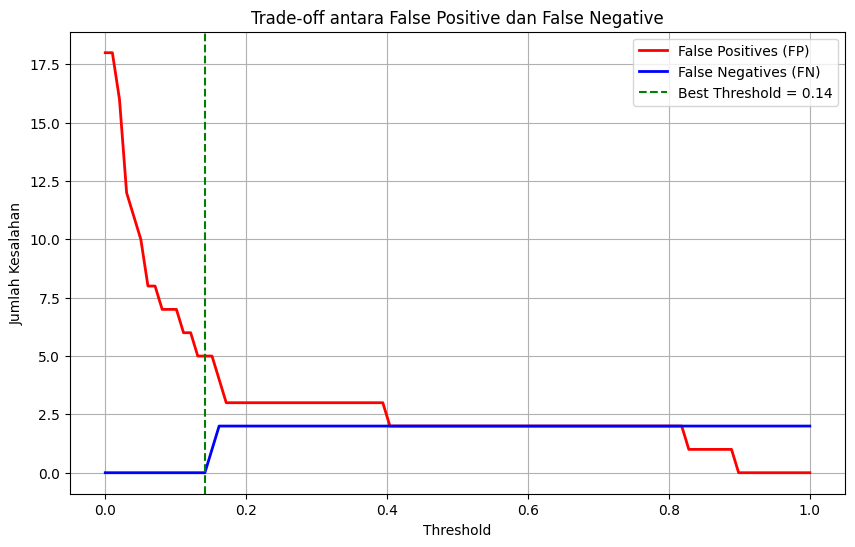

In [90]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Prediksi probabilitas
y_prob = best_xgb.predict_proba(X_test)[:, 1]

# Buat threshold range dari 0 sampai 1
thresholds = np.linspace(0, 1, 100)

# Simpan FP dan FN untuk tiap threshold
fp_list = []
fn_list = []

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    fp_list.append(fp)
    fn_list.append(fn)

# Plot
plt.figure(figsize=(10,6))
plt.plot(thresholds, fp_list, label='False Positives (FP)', color='red', linewidth=2)
plt.plot(thresholds, fn_list, label='False Negatives (FN)', color='blue', linewidth=2)
plt.axvline(best_threshold, color='green', linestyle='--', label=f'Best Threshold = {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('Jumlah Kesalahan')
plt.title('Trade-off antara False Positive dan False Negative')
plt.legend()
plt.grid(True)
plt.show()


Plot menunjukkan jumlah False Positives (FP) (merah) dan False Negatives (FN) (biru) terhadap berbagai threshold prediksi probabilitas churn. Dari plot, terlihat:

- Threshold rendah → FP tinggi, FN rendah
Jika threshold diturunkan terlalu rendah (misal mendekati 0), hampir semua pelanggan diprediksi akan churn. Akibatnya, model banyak over-prediksi churn (FP tinggi), tapi hampir tidak ada pelanggan churn yang terlewat (FN rendah). Artinya, kita “aman” dari kehilangan pelanggan yang benar-benar churn, tapi banyak pelanggan yang sebenarnya aman diprediksi churn.
- Threshold tinggi → FP rendah, FN tinggi
Jika threshold dinaikkan mendekati 1, model sangat konservatif dalam memprediksi churn. Akibatnya, FP turun drastis, tapi model melewatkan banyak pelanggan yang benar-benar churn (FN naik).Artinya, kita tidak salah menandai pelanggan aman sebagai churn, tapi risiko kehilangan pelanggan yang benar-benar akan churn meningkat.
- Threshold optimal (~0.14, garis hijau)
Titik ini dipilih untuk menyeimbangkan trade-off antara FP dan FN menggunakan Youden Index. FP dan FN relatif seimbang di titik ini untuk dataset kecilmu, sehingga model tidak terlalu over-predict maupun under-predict churn.

Trade-off FP vs FN berarti kita harus memilih threshold dengan bijak: menurunkan threshold menurunkan risiko kehilangan pelanggan (FN) tapi meningkatkan false alarm (FP), sementara menaikkan threshold mengurangi false alarm tapi meningkatkan risiko melewatkan pelanggan yang churn. Threshold optimal membantu menyeimbangkan kedua risiko tersebut.